# Раздел: Доставка (участник: Alisher)

**Трек D — OqPay Super-App**

**Гипотеза:** в августе 2025 произошёл локализованный сбой в логистике Самарканда — доля просроченных доставок выросла с обычных ~9% до 93.5%, при этом объём заказов, число активных курьеров и нагрузка на курьера оставались в норме. Это указывает на внешний/инфраструктурный сбой, специфичный именно для города, а не на нехватку курьеров или рост спроса.

## Подключение к базе

In [18]:
# !pip install psycopg2-binary pandas matplotlib scipy statsmodels

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import psycopg2

MY_LOGIN = 'asabirov'
MY_PASSWORD = 'Asabirov@Db5955'

conn = psycopg2.connect(
    host='thomas.proxy.rlwy.net',
    port=51432,
    dbname='academy_db',
    user=MY_LOGIN,
    password=MY_PASSWORD,
    sslmode='require'
)

def sql(query):
    """Выполнить SQL и вернуть результат как DataFrame."""
    return pd.read_sql(query, conn)

print('Подключено')

Подключено


## Шаг 1. Общая динамика доставок и просрочек по месяцам

In [19]:
df_overall = sql("""
    SELECT
        date_trunc('month', promised_ts) AS ym,
        COUNT(*) AS delivery_count,
        AVG(EXTRACT(EPOCH FROM (delivered_ts - promised_ts)) / 60) AS avg_delay_minutes,
        SUM(CASE WHEN status = 'late' THEN 1 ELSE 0 END) AS late_count,
        ROUND(100.0 * SUM(CASE WHEN status = 'late' THEN 1 ELSE 0 END) / COUNT(*), 2) AS late_pct
    FROM ds_deliveries
    GROUP BY date_trunc('month', promised_ts)
    ORDER BY ym
""")
df_overall

/var/folders/ch/fyp9js953h77f_wvqmdx9n280000gn/T/ipykernel_21173/3038870805.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, conn)


,ym,delivery_count,avg_delay_minutes,late_count,late_pct
0,2025-01-01,5639,144.981009,486,8.62
1,2025-02-01,5751,141.542837,492,8.56
2,2025-03-01,7113,145.002867,622,8.74
3,2025-04-01,6981,147.236034,616,8.82
4,2025-05-01,7587,142.062382,632,8.33
5,2025-06-01,7796,147.086387,725,9.30
6,2025-07-01,8516,145.734801,786,9.23
7,2025-08-01,8782,720.913777,1621,18.46
8,2025-09-01,9136,143.272158,759,8.31
9,2025-10-01,9869,142.518626,803,8.14


**Вывод:** в августе 2025 средняя задержка доставки взлетает до ~720 минут против обычных ~140-145 минут в остальные месяцы — аномалия видна на уровне всей системы.

## Шаг 2. Локализация по городам (август 2025)

In [20]:
df_by_city_aug = sql("""
    SELECT
        c.city,
        COUNT(*) AS deliveries_aug,
        SUM(CASE WHEN d.status = 'late' THEN 1 ELSE 0 END) AS late_count,
        ROUND(100.0 * SUM(CASE WHEN d.status = 'late' THEN 1 ELSE 0 END) / COUNT(*), 2) AS late_pct
    FROM ds_deliveries d
    JOIN ds_couriers c ON c.courier_id = d.courier_id
    WHERE date_trunc('month', d.promised_ts) = '2025-08-01'
    GROUP BY c.city
    ORDER BY late_pct DESC
""")
df_by_city_aug

/var/folders/ch/fyp9js953h77f_wvqmdx9n280000gn/T/ipykernel_21173/3038870805.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, conn)


,city,deliveries_aug,late_count,late_pct
0,Samarkand,1033,966,93.51
1,Nukus,443,46,10.38
2,Navoi,459,43,9.37
3,Bukhara,670,60,8.96
4,Jizzakh,369,33,8.94
5,Tashkent,2929,248,8.47
6,Khiva,365,30,8.22
7,Namangan,897,73,8.14
8,Andijan,724,56,7.73
9,Fergana,893,66,7.39


**Вывод:** Самарканд резко выделяется — 93.51% просрочек против 7-10% во всех остальных городах.

## Шаг 3. Самарканд по месяцам — подтверждение, что это разовая аномалия

In [21]:
df_samarkand = sql("""
    SELECT
        date_trunc('month', d.promised_ts) AS ym,
        COUNT(*) AS deliveries,
        SUM(CASE WHEN d.status = 'late' THEN 1 ELSE 0 END) AS late_count,
        ROUND(100.0 * SUM(CASE WHEN d.status = 'late' THEN 1 ELSE 0 END) / COUNT(*), 2) AS late_pct
    FROM ds_deliveries d
    JOIN ds_couriers c ON c.courier_id = d.courier_id
    WHERE c.city = 'Samarkand'
    GROUP BY date_trunc('month', d.promised_ts)
    ORDER BY ym
""")
df_samarkand

/var/folders/ch/fyp9js953h77f_wvqmdx9n280000gn/T/ipykernel_21173/3038870805.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, conn)


,ym,deliveries,late_count,late_pct
0,2025-01-01,698,60,8.60
1,2025-02-01,677,49,7.24
2,2025-03-01,848,70,8.25
3,2025-04-01,841,69,8.20
4,2025-05-01,960,82,8.54
5,2025-06-01,974,68,6.98
6,2025-07-01,1033,104,10.07
7,2025-08-01,1033,966,93.51
8,2025-09-01,1091,100,9.17
9,2025-10-01,1188,102,8.59


In [22]:
df_other = sql("""
    SELECT
        date_trunc('month', d.promised_ts) AS ym,
        COUNT(*) AS deliveries,
        SUM(CASE WHEN d.status = 'late' THEN 1 ELSE 0 END) AS late_count,
        ROUND(100.0 * SUM(CASE WHEN d.status = 'late' THEN 1 ELSE 0 END) / COUNT(*), 2) AS late_pct
    FROM ds_deliveries d
    JOIN ds_couriers c ON c.courier_id = d.courier_id
    WHERE c.city != 'Samarkand'
    GROUP BY date_trunc('month', d.promised_ts)
    ORDER BY ym
""")
df_other

/var/folders/ch/fyp9js953h77f_wvqmdx9n280000gn/T/ipykernel_21173/3038870805.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, conn)


,ym,deliveries,late_count,late_pct
0,2025-01-01,4941,426,8.62
1,2025-02-01,5074,443,8.73
2,2025-03-01,6265,552,8.81
3,2025-04-01,6140,547,8.91
4,2025-05-01,6627,550,8.30
5,2025-06-01,6822,657,9.63
6,2025-07-01,7483,682,9.11
7,2025-08-01,7749,655,8.45
8,2025-09-01,8045,659,8.19
9,2025-10-01,8681,701,8.08


## Шаг 4. Исключаем версии "не хватило курьеров" / "конкретные курьеры виноваты"

In [23]:
# late_pct по каждому курьеру Самарканда в августе
df_couriers_aug = sql("""
    SELECT
        c.courier_id,
        c.vehicle_type,
        c.active,
        COUNT(*) AS deliveries,
        SUM(CASE WHEN d.status = 'late' THEN 1 ELSE 0 END) AS late_count,
        ROUND(100.0 * SUM(CASE WHEN d.status = 'late' THEN 1 ELSE 0 END) / COUNT(*), 2) AS late_pct
    FROM ds_deliveries d
    JOIN ds_couriers c ON c.courier_id = d.courier_id
    WHERE c.city = 'Samarkand'
      AND date_trunc('month', d.promised_ts) = '2025-08-01'
    GROUP BY c.courier_id, c.vehicle_type, c.active
    ORDER BY late_pct DESC
""")
df_couriers_aug

/var/folders/ch/fyp9js953h77f_wvqmdx9n280000gn/T/ipykernel_21173/3038870805.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, conn)


,courier_id,vehicle_type,active,deliveries,late_count,late_pct
0,116,bike,True,13,13,100.00
1,203,car,True,20,20,100.00
2,197,scooter,True,18,18,100.00
3,150,car,True,26,26,100.00
4,38,bike,True,19,19,100.00
5,45,foot,True,22,22,100.00
6,140,scooter,True,20,20,100.00
7,67,scooter,True,26,26,100.00
8,81,car,True,23,23,100.00
9,131,car,True,15,15,100.00


In [24]:
# нагрузка на курьера по месяцам в Самарканде
df_load = sql("""
    SELECT
        date_trunc('month', d.promised_ts) AS ym,
        COUNT(DISTINCT d.courier_id) AS active_couriers,
        COUNT(*) AS deliveries,
        ROUND(COUNT(*)::numeric / COUNT(DISTINCT d.courier_id), 1) AS deliveries_per_courier
    FROM ds_deliveries d
    JOIN ds_couriers c ON c.courier_id = d.courier_id
    WHERE c.city = 'Samarkand'
      AND d.promised_ts >= '2025-06-01' AND d.promised_ts < '2025-10-01'
    GROUP BY date_trunc('month', d.promised_ts)
    ORDER BY ym
""")
df_load

/var/folders/ch/fyp9js953h77f_wvqmdx9n280000gn/T/ipykernel_21173/3038870805.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, conn)


,ym,active_couriers,deliveries,deliveries_per_courier
0,2025-06-01,47,974,20.7
1,2025-07-01,47,1033,22.0
2,2025-08-01,47,1033,22.0
3,2025-09-01,47,1091,23.2


**Вывод:** late_pct под 90-100% практически у всех курьеров Самарканда одновременно, независимо от типа транспорта. Число активных курьеров стабильно (47) весь период, нагрузка на курьера росла плавно и в сентябре была даже выше, чем в августе — при этом late_pct вернулся к норме. Значит проблема не в нехватке курьеров и не в перегрузке — это системный сбой, затронувший весь город разом.

## Шаг 5. Разрез по дням августа — весь месяц или конкретный период?

In [25]:
df_august_days = sql("""
    SELECT
        d.promised_ts::date AS day,
        COUNT(*) AS deliveries,
        SUM(CASE WHEN d.status = 'late' THEN 1 ELSE 0 END) AS late_count,
        ROUND(100.0 * SUM(CASE WHEN d.status = 'late' THEN 1 ELSE 0 END) / COUNT(*), 2) AS late_pct
    FROM ds_deliveries d
    JOIN ds_couriers c ON c.courier_id = d.courier_id
    WHERE c.city = 'Samarkand'
      AND d.promised_ts >= '2025-08-01' AND d.promised_ts < '2025-09-01'
    GROUP BY d.promised_ts::date
    ORDER BY day
""")
df_august_days

/var/folders/ch/fyp9js953h77f_wvqmdx9n280000gn/T/ipykernel_21173/3038870805.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, conn)


,day,deliveries,late_count,late_pct
0,2025-08-02,13,13,100.00
1,2025-08-03,24,22,91.67
2,2025-08-04,32,30,93.75
3,2025-08-05,37,34,91.89
4,2025-08-06,42,40,95.24
5,2025-08-07,35,33,94.29
6,2025-08-08,40,36,90.00
7,2025-08-09,36,31,86.11
8,2025-08-10,34,34,100.00
9,2025-08-11,33,32,96.97


**Вывод:** сбой держался равномерно (78-100% late) каждый день августа, без "спокойных" дней внутри месяца, и так же резко закончился 1 сентября — это системная проблема, работавшая весь месяц, а не разовый инцидент на пару дней.

## Статистическая проверка (z-test для разницы долей)

In [26]:
from statsmodels.stats.proportion import proportions_ztest

# август Самарканд: 966 late из 1033
# остальные месяцы Самарканд: 911 late из 11101
count = [966, 911]
nobs = [1033, 11101]

z_stat, p_value = proportions_ztest(count, nobs)

print(f"Доля late в августе: {966/1033:.2%}")
print(f"Доля late в остальные месяцы: {911/11101:.2%}")
print(f"z-статистика: {z_stat:.2f}")
print(f"p-value: {p_value:.2e}")

Доля late в августе: 93.51%
Доля late в остальные месяцы: 8.21%
z-статистика: 72.52
p-value: 0.00e+00


In [27]:
# доверительный интервал для разницы долей
p1, n1 = 966/1033, 1033
p2, n2 = 911/11101, 11101

diff = p1 - p2
se = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
ci_low, ci_high = diff - 1.96*se, diff + 1.96*se

print(f"Разница долей: {diff:.2%}")
print(f"95% доверительный интервал: [{ci_low:.2%}, {ci_high:.2%}]")

Разница долей: 85.31%
95% доверительный интервал: [83.72%, 86.89%]


**Вывод:** разница долей просрочек статистически значима (p << 0.001) — это не случайное отклонение.

## Графики

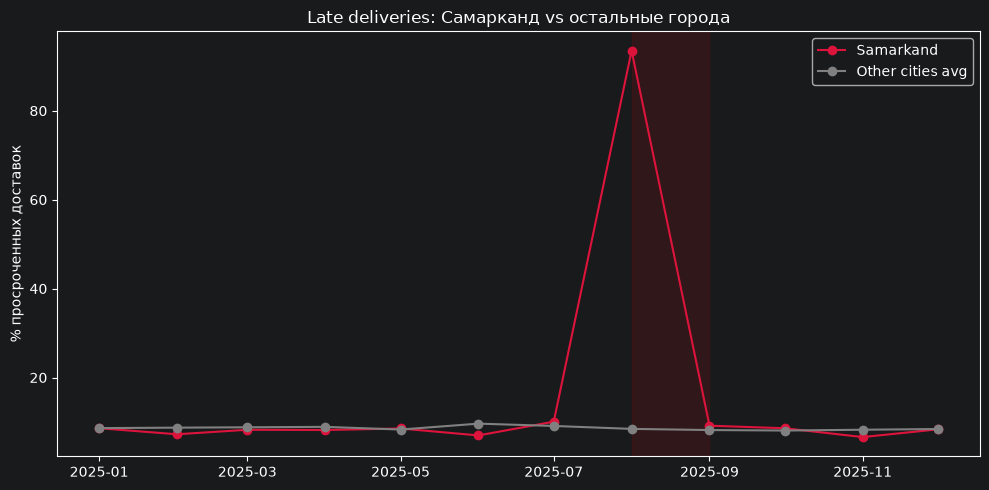

In [28]:
# график 1: динамика late_pct по месяцам, Самарканд vs остальные
plt.figure(figsize=(10, 5))
plt.plot(df_samarkand['ym'], df_samarkand['late_pct'], marker='o', label='Samarkand', color='crimson')
plt.plot(df_other['ym'], df_other['late_pct'], marker='o', label='Other cities avg', color='gray')
plt.axvspan(pd.Timestamp('2025-08-01'), pd.Timestamp('2025-09-01'), color='red', alpha=0.1)
plt.ylabel('% просроченных доставок')
plt.title('Late deliveries: Самарканд vs остальные города')
plt.legend()
plt.tight_layout()
plt.show()

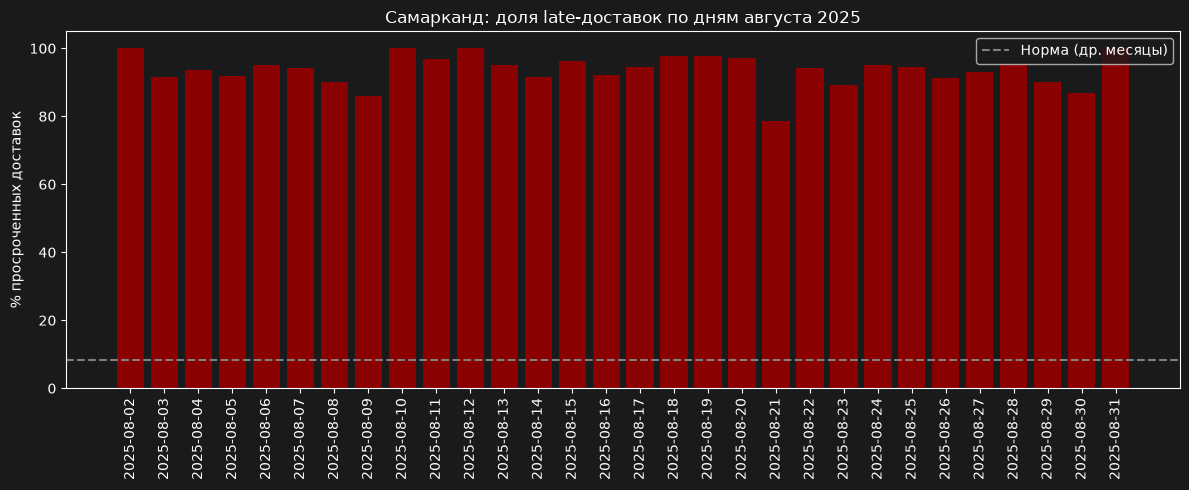

In [29]:
# график 2: день за днём по августу в Самарканде
plt.figure(figsize=(12, 5))
plt.bar(df_august_days['day'].astype(str), df_august_days['late_pct'], color='darkred')
plt.axhline(y=8.21, color='gray', linestyle='--', label='Норма (др. месяцы)')
plt.xticks(rotation=90)
plt.ylabel('% просроченных доставок')
plt.title('Самарканд: доля late-доставок по дням августа 2025')
plt.legend()
plt.tight_layout()
plt.show()

## Итоговый вывод и рекомендация

**Находка:** в августе 2025 в Самарканде произошёл системный сбой доставки — доля просрочек выросла с обычных ~9% до 93.5% (p < 0.001, 95% ДИ разницы долей [83.7%, 86.9%]). Проверены и исключены версии "не хватило курьеров" и "виноваты конкретные курьеры/транспорт" — сбой затронул весь город равномерно на протяжении всего месяца, что указывает на внешнюю/инфраструктурную причину.

**Рекомендация:** настроить мониторинг доли late-доставок по городам в реальном времени с алертом при отклонении от нормы (например, более чем в 2 раза от скользящего среднего за 7 дней), чтобы подобные локальные сбои выявлялись за дни, а не постфактум через месяц по логам.

In [30]:
conn.close()
print('Соединение закрыто')

Соединение закрыто
